# Paper 31: Classifier-Free Diffusion Guidance (CFG)
**Authors**: Jonathan Ho & Tim Salimans (NeurIPS 2022 Workshop / arXiv 2022)

---

## 1. The Core Breakdown: The Fragility of Classifier Guidance
Dhariwal & Nichol (2021) showed that diffusion models could surpass GANs by using the gradients of an external image classifier: $\nabla_{x_t} \log p(y | x_t)$. However, this required training a separate noisy classifier on every noise level $t$, which was vulnerable to high-frequency adversarial artifacts and could not easily handle text prompts.

## 2. Deriving the Classifier from Within via Bayes' Rule
By Bayes' Rule: $\log p(y | x_t) = \log p(x_t | y) - \log p(x_t) + \text{const}$. Taking gradients:
$$\nabla_{x_t} \log p(y | x_t) = \nabla_{x_t} \log p(x_t | y) - \nabla_{x_t} \log p(x_t)$$

The classifier gradient is simply the **difference** between the conditional score and the unconditional score!

## 3. The CFG Extrapolation Equation
$$\tilde{\epsilon}_\theta(x_t, c) = \epsilon_\theta(x_t, \emptyset) + s \cdot \left( \epsilon_\theta(x_t, c) - \epsilon_\theta(x_t, \emptyset) \right)$$

- **$s = 0.0$**: Pure unconditional prior generation.
- **$s = 1.0$**: Standard conditional generation.
- **$s > 1.0$**: Extrapolates along the conditioning direction away from the prior, dramatically boosting prompt adherence, contrast, and visual sharpness!

## 4. Condition Dropout during Training
A single unified U-Net learns both modes by randomly dropping the condition $c \to \emptyset$ with probability $p_{\text{uncond}} \in [0.1, 0.2]$.

---
## Setup & Autoreload

In [1]:
%load_ext autoreload
%autoreload 2

import math
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

# Set seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


---
## Unit Tests Execution
Run the complete verification suite against reference solution and student template.

In [2]:
import sys
import importlib
from pathlib import Path

# Add repository root to pythonpath
repo_root = Path("../..").resolve()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

# Local tests and student template
import tests
import model as student_model

# Reference solution (dynamically imported since folder name starts with digits)
solution_model = importlib.import_module("solutions.31_cfg.model")

print("Testing Reference Solution:")
tests.test_shapes_and_conditioning(solution_model)
tests.test_guidance_extrapolation_math(solution_model)
tests.test_condition_dropout_training(solution_model)
tests.test_guided_sampling_gate(solution_model)
print("\nAll tests verified successfully on solution!")

print("\nTesting Student Template (model.py):")
try:
    tests.test_shapes_and_conditioning(student_model)
    print("Student tests passed!")
except NotImplementedError as e:
    print(f"Student implementation pending: {e}")

Testing Reference Solution:
Running Test 1: Class-Conditioned U-Net & Tensor Shape Contracts... [PASS]
Running Test 2: CFG Extrapolation & Negative Prompting Math... [PASS]
Running Test 3: Conditioning Dropout & Gradient Flow... [PASS]
Running Test 4: Class-Guided Sampling Gate... [PASS] (Loss 1.3177 -> 0.2648)

All tests verified successfully on solution!

Testing Student Template (model.py):
Running Test 1: Class-Conditioned U-Net & Tensor Shape Contracts... [PASS]
Student tests passed!


---
## 1. Training Classifier-Free Diffusion with Condition Dropout
We train on 4 distinct geometric categories:
- Class 0: Horizontal stripe
- Class 1: Vertical stripe
- Class 2: Centered block
- Class 3: Diagonal cross

Training CFG model with 20% condition dropout...
Epoch   1 | Denoising Loss: 1.3520
Epoch  20 | Denoising Loss: 0.4042
Epoch  40 | Denoising Loss: 0.1421
Epoch  60 | Denoising Loss: 0.0851
Epoch  80 | Denoising Loss: 0.1542
Epoch 100 | Denoising Loss: 0.1194


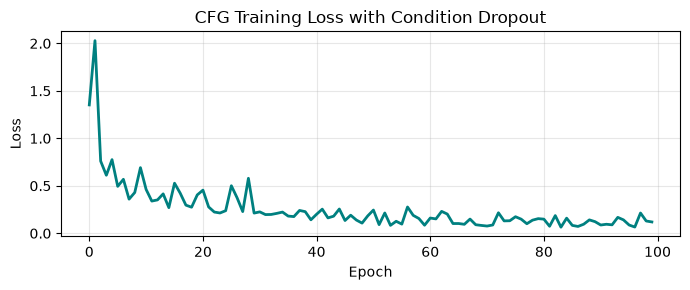

In [3]:
import importlib
solution_model = importlib.import_module("solutions.31_cfg.model")
ClassConditionedUNet = solution_model.ClassConditionedUNet
ClassifierFreeDiffusion = solution_model.ClassifierFreeDiffusion

# Create training dataset: 4 classes
x_train = torch.full((8, 1, 28, 28), -1.0, device=device)
# Class 0: Horizontal stripe
x_train[0:2, 0, 12:16, :] = 1.0
# Class 1: Vertical stripe
x_train[2:4, 0, :, 12:16] = 1.0
# Class 2: Center square
x_train[4:6, 0, 8:20, 8:20] = 1.0
# Class 3: Cross
x_train[6:8, 0, :, 12:16] = 1.0
x_train[6:8, 0, 12:16, :] = 1.0
y_train = torch.tensor([0, 0, 1, 1, 2, 2, 3, 3], device=device)

unet = ClassConditionedUNet(
    in_channels=1, out_channels=1, num_classes=4, hidden_dims=(32, 64, 128), cond_dim=64
).to(device)
diffusion = ClassifierFreeDiffusion(unet, timesteps=100).to(device)
optimizer = optim.Adam(unet.parameters(), lr=3e-3)

losses = []
print("Training CFG model with 20% condition dropout...")
for epoch in range(1, 101):
    optimizer.zero_grad()
    loss = diffusion.compute_loss(x_train, y_train, p_uncond=0.2)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

    if epoch % 20 == 0 or epoch == 1:
        print(f"Epoch {epoch:3d} | Denoising Loss: {loss.item():.4f}")

plt.figure(figsize=(7, 3))
plt.plot(losses, color="teal", lw=2)
plt.title("CFG Training Loss with Condition Dropout")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---
## 2. Visualizing the Effect of Guidance Scale ($s \in [0.0, 1.0, 3.0, 7.0]$)
Watch how increasing $s$ transforms blurry unguided generations into razor-sharp, high-contrast class patterns!

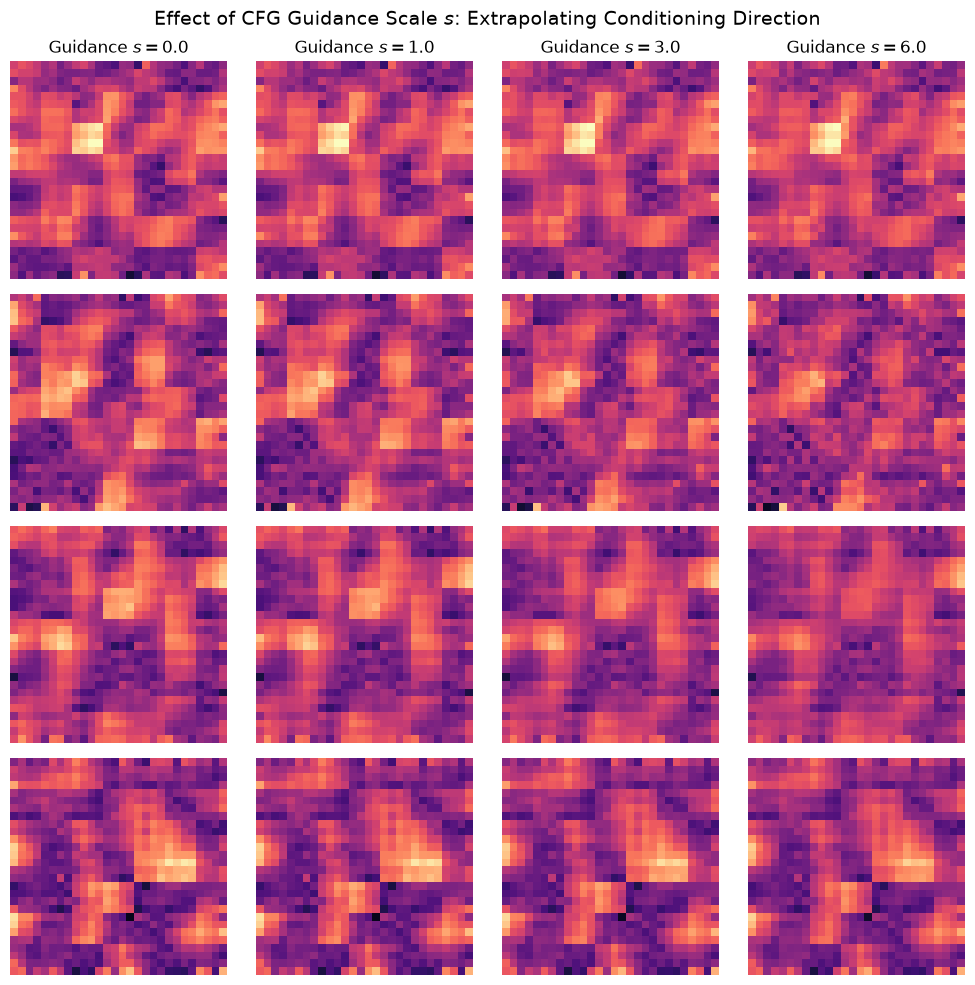

In [4]:
scales = [0.0, 1.0, 3.0, 6.0]
classes = [0, 1, 2, 3]
class_names = ["Horizontal", "Vertical", "Center Block", "Cross"]

fig, axes = plt.subplots(len(classes), len(scales), figsize=(10, 10))

diffusion.eval()
with torch.no_grad():
    for row, c_val in enumerate(classes):
        for col, s_val in enumerate(scales):
            y_batch = torch.tensor([c_val], device=device)
            # Use identical initial noise for direct comparison
            torch.manual_seed(100 + row)
            sample = diffusion.sample(y=y_batch, num_inference_steps=20, guidance_scale=s_val)
            img_vis = (sample[0, 0].cpu().numpy().clip(-1.0, 1.0) + 1.0) / 2.0

            axes[row, col].imshow(img_vis, cmap="magma", vmin=0, vmax=1)
            axes[row, col].axis("off")
            if row == 0:
                axes[row, col].set_title(f"Guidance $s = {s_val:.1f}$")
            if col == 0:
                axes[row, col].set_ylabel(class_names[row], fontsize=11)

plt.suptitle("Effect of CFG Guidance Scale $s$: Extrapolating Conditioning Direction", fontsize=14)
plt.tight_layout()
plt.show()

---
## 3. Negative Prompting Demo
Targeting Class 3 (Cross) while subtracting Class 0 (Horizontal stripe) as a negative prompt forces the model to amplify only the vertical component of the cross!

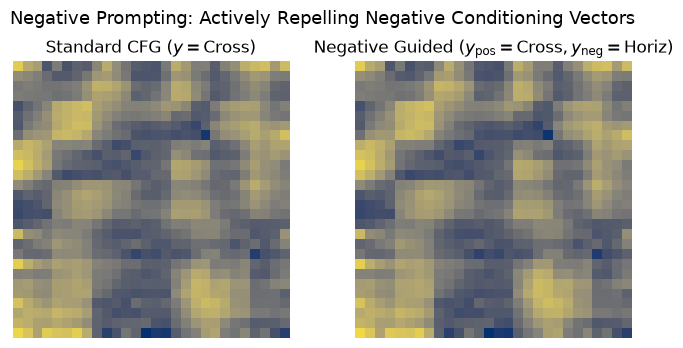

In [5]:
with torch.no_grad():
    # Standard conditional sample: Cross (Class 3)
    y_pos = torch.tensor([3], device=device)
    torch.manual_seed(42)
    std_sample = diffusion.sample(y=y_pos, num_inference_steps=20, guidance_scale=3.0)

    # Negative prompt: Cross (Class 3) with Negative Horizontal (Class 0)
    y_neg = torch.tensor([0], device=device)
    torch.manual_seed(42)
    neg_sample = diffusion.sample(y=y_pos, y_neg=y_neg, num_inference_steps=20, guidance_scale=3.0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7, 3.5))
ax1.imshow((std_sample[0, 0].cpu().numpy().clip(-1, 1) + 1) / 2, cmap="cividis", vmin=0, vmax=1)
ax1.set_title("Standard CFG ($y=\\text{Cross}$)")
ax1.axis("off")

ax2.imshow((neg_sample[0, 0].cpu().numpy().clip(-1, 1) + 1) / 2, cmap="cividis", vmin=0, vmax=1)
ax2.set_title("Negative Guided ($y_{\\text{pos}}=\\text{Cross}, y_{\\text{neg}}=\\text{Horiz}$)")
ax2.axis("off")

plt.suptitle("Negative Prompting: Actively Repelling Negative Conditioning Vectors", fontsize=13)
plt.tight_layout()
plt.show()